In [2]:
# from matplotlib_venn import venn2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

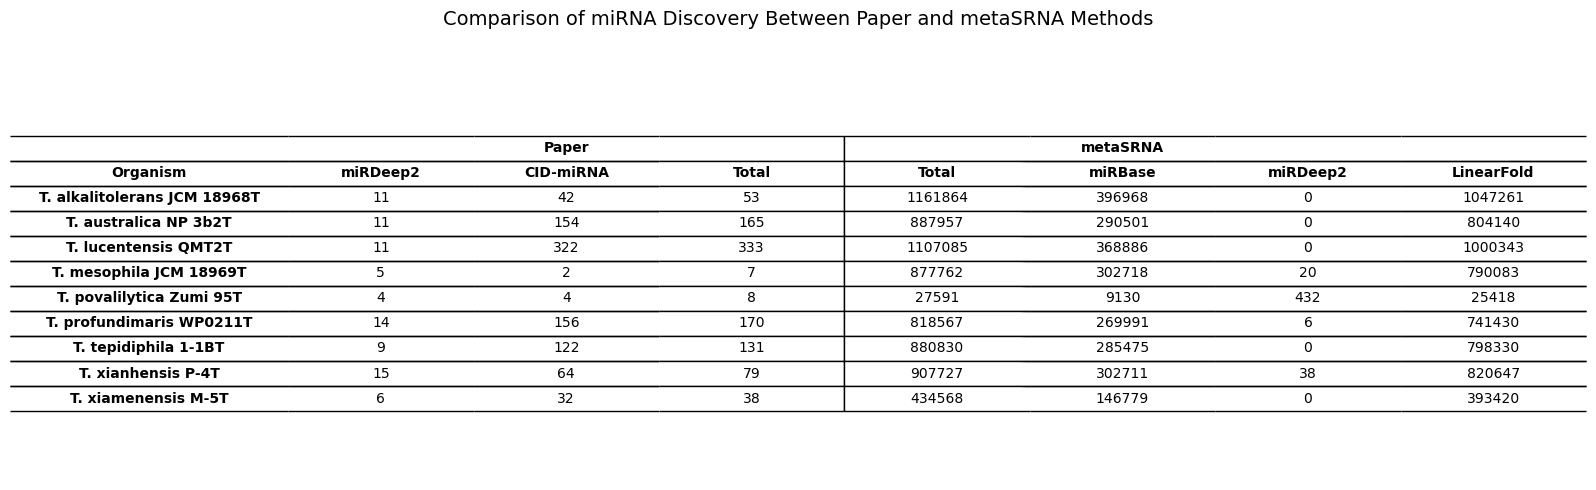

In [12]:
import matplotlib.pyplot as plt


header_1 = ['', '', '', '', 'metaSRNA(filter_100_100)', '', '', '']
header_2 = ['Organism', 'miRDeep2', 'CID-miRNA', 'Total', 'Total', 'miRBase', 'miRDeep2', 'LinearFold']
data_rows = [
    #530
    #529
    
    ['T. alkalitolerans JCM 18968T', 11, 42, 53, 1161864, 396968, 0, 1047261],
    ['T. australica NP 3b2T', 11, 154, 165, 887957, 290501, 0, 804140],
    ['T. lucentensis QMT2T', 11, 322, 333, 1107085,368886, 0, 1000343],
    ['T. mesophila JCM 18969T', 5, 2, 7,877762, 302718, 20, 790083 ],
    ['T. povalilytica Zumi 95T', 4, 4, 8, 27591, 9130, 432, 25418],
    ['T. profundimaris WP0211T', 14, 156, 170, 818567, 269991, 6, 741430],
    ['T. tepidiphila 1-1BT', 9, 122, 131, 880830, 285475, 0, 798330],
    ['T. xianhensis P-4T', 15, 64, 79, 907727, 302711, 38, 820647],
    ['T. xiamenensis M-5T', 6, 32, 38, 434568, 146779, 0, 393420]
]


table_data = [header_1, header_2] + data_rows


fig, ax = plt.subplots(figsize=(16, 5))
ax.axis('off')

table = ax.table(
    cellText=table_data,
    cellLoc='center',
    colWidths=[0.15] + [0.1] * 7,
    loc='center'
)

for col in range(8):
    cell = table[(0, col)]
    if col == 0:
        cell.set_facecolor('#ffffff')
        cell.set_text_props(weight='bold')
    elif 1 <= col <= 3:
        # cell.set_facecolor('#c7d7e8')
        if col == 2:
            cell.get_text().set_text('Paper')
        else:
            cell.get_text().set_text('')
    elif 4 <= col <= 7:
        # cell.set_facecolor('#fde9d9')
        if col == 5:
            cell.get_text().set_text('metaSRNA')
        else:
            cell.get_text().set_text('')
    cell.set_text_props(weight='bold')
    cell.visible_edges = 'TB'
    if col == 3:
        cell.visible_edges += 'R'
    elif col == 4:
        cell.visible_edges += 'L'

for col in range(8):
    cell = table[(1, col)]
    # cell.set_facecolor('#eaf1fb' if col <= 3 else '#fdebd0')
    cell.set_text_props(weight='bold')
    cell.visible_edges = 'TB'
    if col == 3:
        cell.visible_edges += 'R'
    elif col == 4:
        cell.visible_edges += 'L'

for row in range(2, len(table_data)):
    for col in range(8):
        cell = table[(row, col)]
        if col == 0:
            cell.set_text_props(weight='bold')
        cell.visible_edges = 'TB'
        if col == 3:
            cell.visible_edges += 'R'
        elif col == 4:
            cell.visible_edges += 'L'

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.4)

plt.title("Comparison of miRNA Discovery Between Paper and metaSRNA Methods", fontsize=14, pad=30)
plt.tight_layout()
plt.show()

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Samples": [
        "T. australica NP 3b2T", "T. alkalitolerans JCM 18968T", "T. lucentensis QMT2T",
        "T. mesophila JCM 18969T", "T. povalilytica Zumi 95T", "T. profundimaris WP0211T",
        "T. tepidiphila 1-1BT", "T. xiamenensis M-5T", "T. xianhensis P-4T"
    ],
    "Sample IDs": [
        "SRR8195529","SRR8195530","SRR8195531",
        "SRR8195532","SRR8195525","SRR8195526",
        "SRR8195527","SRR8195528","SRR8195524"
    ],
    "Original reads (Paper)": ["229,991,595", "31,431,409", "28,737,289", "27,213,115", "28,225,762", "25,272,618", "25,641,708", "28,144,650", "24,546,591"],
    "Original reads (metaSRNA)": ["229,991,595", "31,431,409", "28,737,289", "27,213,115", "28,225,762", "25,272,618", "25,641,708", "28,144,650", "24,546,591"],
    "Filtered reads (Paper)": ["3,177,403", "5,068,260", "4,606,730", "2,954,668", "3,761,719", "5,327,201", "4,368,445", "1,712,391", "3,300,999"],
    "Filtered reads (metaSRNA(READS LEN>=18))": ["17,233,903", "24,290,216", "21,404,746","22,513,448","24,789,920","19,153,723","16,903,484","27,157,471","17,112,451" ],
    "Aligned reads (Paper)": ["2,285,671", "160,990", "2,511,917", "102,497", "95,972", "2,046,567", "1,230,299", "1,143,173", "631,902"],
    "Aligned reads (metaSRNA(100,100))": ["14,571,892", "19,826,644","17,362,287", "17,448,620","9,742,753","13,005,035","12,027,953","25,508,890","11,332,664"],
    "Aligned % (Paper)": [71.94, 3.18, 54.53, 3.47, 2.55, 38.42, 28.16, 66.76, 19.14],
    "Aligned % (metaSRNA(100,100))": [84.55, 81.62, 81.11, 77.50, 39.30, 67.90, 71.16,93.93,66.22],
    "reference (Paper)": [
        "T. australica NP 3b2T", "T. lucentensis QMT2T", "T. lucentensis QMT2T",
        "T. lucentensis QMT2T", "T. profundimaris WP0211T", "T. profundimaris WP0211T",
        "T. profundimaris WP0211T", "T. xiamenensis M-5T", "T. xiamenensis M-5T"
    ],
    "Reference (metaSRNA)": [
        "T. australica NP 3b2T", "T. alkalitolerans JCM 18968", "T. lucentensis QMT2T",
        "T. mesophila JCM 18969", "T. povalilytica Zumi 95", "T. profundimaris WP0211T",
        "Thalassospira tepidiphila MCCC 1A03514", "T. xiamenensis M-5T", "Thalassospira xianhensis MCCC 1A02616"
    ]
}

df = pd.DataFrame(data)

row_order = [   "SRR8195524","SRR8195525","SRR8195526",
                "SRR8195527","SRR8195528","SRR8195529",
                "SRR8195530","SRR8195531","SRR8195532"]

df = df.set_index("Sample IDs").loc[row_order].reset_index()


df.to_excel("Supplementary_Table_6.xlsx", index=False, header=True)

